In [95]:
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from pathlib import Path
from paddleocr import PaddleOCR
import json
import re
from jiwer import cer, wer
from difflib import unified_diff

# Read data 

In [2]:
# Dataset path
images_path = Path("dataset/training_data/images")

# Get all PNG images
image_files = sorted(images_path.glob("*.png"))

print("Total Training Images:", len(image_files))

Total Training Images: 149


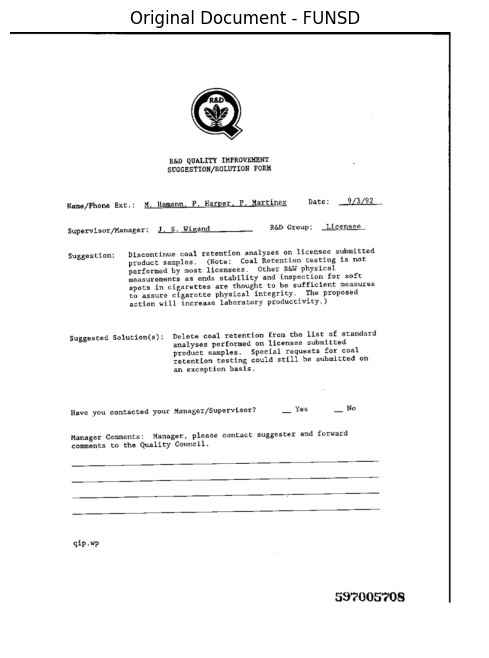

Image Name: 0000971160.png
Image Shape: (1000, 762, 3)


In [3]:
# Read first document
image_path = image_files[0]
image = cv2.imread(str(image_path))

if image is None:
    raise ValueError("Failed to load image")

# Convert BGR to RGB
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Display document
plt.figure(figsize=(10, 8))
plt.imshow(image_rgb)
plt.title("Original Document - FUNSD")
plt.axis("off")
plt.show()

print("Image Name:", image_path.name)
print("Image Shape:", image.shape)


# Image Preprocessing

In [4]:
# Convert image to gray scale
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

In [5]:
# Apply Gaussian Blur
blurred = cv2.GaussianBlur(gray, (5, 5), 0)

Display results

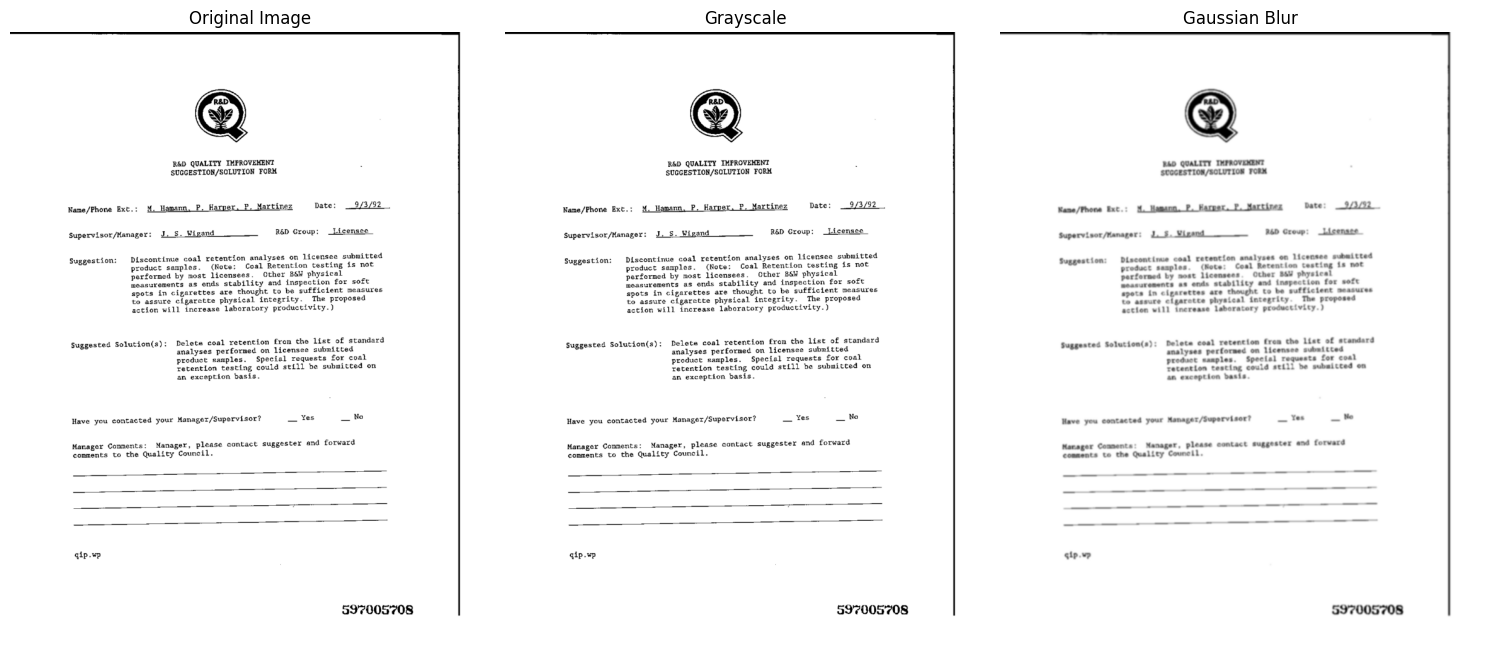

In [6]:
plt.figure(figsize=(15, 10))

plt.subplot(1, 3, 1)
plt.imshow(image_rgb)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(gray, cmap="gray")
plt.title("Grayscale")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(blurred, cmap="gray")
plt.title("Gaussian Blur")
plt.axis("off")

plt.tight_layout()
plt.show()


In [7]:
# Apply Canny Edge Detection
edges = cv2.Canny(blurred, 50, 150)

Display results using Canny


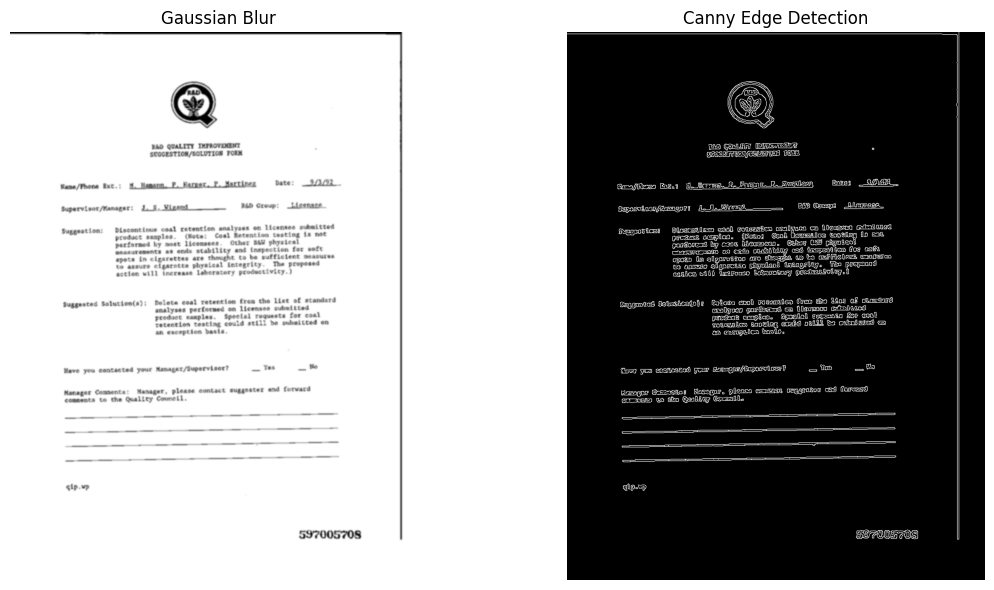

Edges Shape: (1000, 762)


In [8]:
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(blurred, cmap="gray")
plt.title("Gaussian Blur")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(edges, cmap="gray")
plt.title("Canny Edge Detection")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Edges Shape:", edges.shape)


In [9]:
# Find contours
contours, hierarchy = cv2.findContours(edges,cv2.RETR_LIST,cv2.CHAIN_APPROX_SIMPLE)
print("Total Contours:", len(contours))

Total Contours: 1218


In [10]:
# Sort contours by area
contours = sorted(contours,key=cv2.contourArea,reverse=True)

In [11]:
# Draw the 10 largest contours
contour_image = image.copy()

cv2.drawContours(contour_image,contours[:10],-1,(0, 0, 255),2)

array([[[  0,   0,   0],
        [  0,   0,   0],
        [  0,   0,   0],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[  0,   0,   0],
        [  0,   0,   0],
        [  0,   0,   0],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[  0,   0,   0],
        [  0,   0,   0],
        [  0,   0,   0],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       ...,

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]]

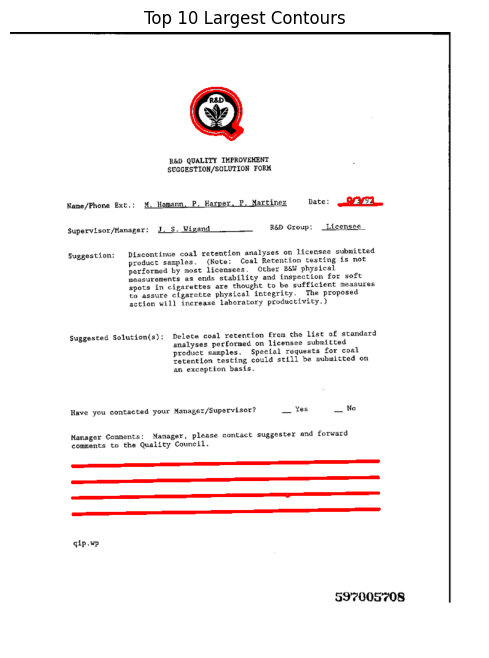

In [12]:
# Display result
plt.figure(figsize=(10, 8))
plt.imshow(cv2.cvtColor(contour_image, cv2.COLOR_BGR2RGB))
plt.title("Top 10 Largest Contours")
plt.axis("off")
plt.show()

In [13]:
approx_image = image.copy()

for contour in contours[:10]:

    # Calculate contour perimeter
    perimeter = cv2.arcLength(contour, True)

    # Approximate contour shape
    approx = cv2.approxPolyDP(contour,0.02 * perimeter,True)

    print("Number of corners:", len(approx))

    # Draw contours with exactly 4 vertices
    if len(approx) == 4:
        cv2.drawContours(approx_image,[approx],-1,(0, 0, 255),3)


Number of corners: 9
Number of corners: 11
Number of corners: 9
Number of corners: 11
Number of corners: 2
Number of corners: 2
Number of corners: 2
Number of corners: 2
Number of corners: 10
Number of corners: 2


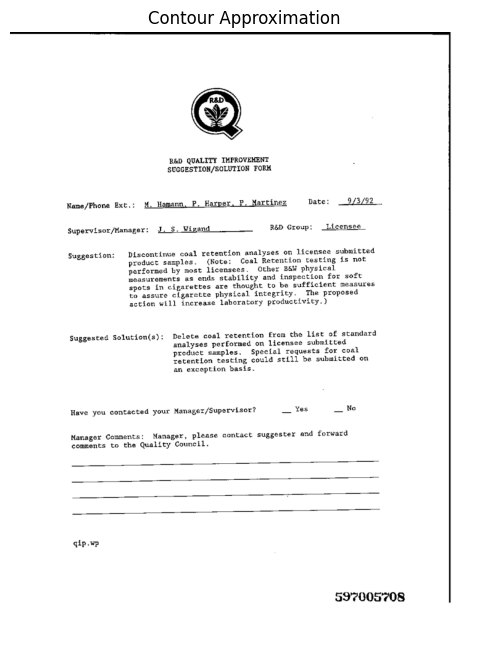

In [14]:
# Display result
plt.figure(figsize=(10, 8))
plt.imshow(cv2.cvtColor(approx_image, cv2.COLOR_BGR2RGB))
plt.title("Contour Approximation")
plt.axis("off")
plt.show()

In [15]:
# Load tilted document
tilted_image = cv2.imread("sample_images/document_tilted.jpg")

if tilted_image is None:
    raise FileNotFoundError("Document image not found")


In [16]:
# Convert to gray scale
tilted_gray = cv2.cvtColor(tilted_image,cv2.COLOR_BGR2GRAY)

# Apply Gaussian Blur
tilted_blurred = cv2.GaussianBlur(tilted_gray, (5, 5), 0)

# Detect edges
tilted_edges = cv2.Canny(tilted_blurred, 50, 150)

Display results a new image 


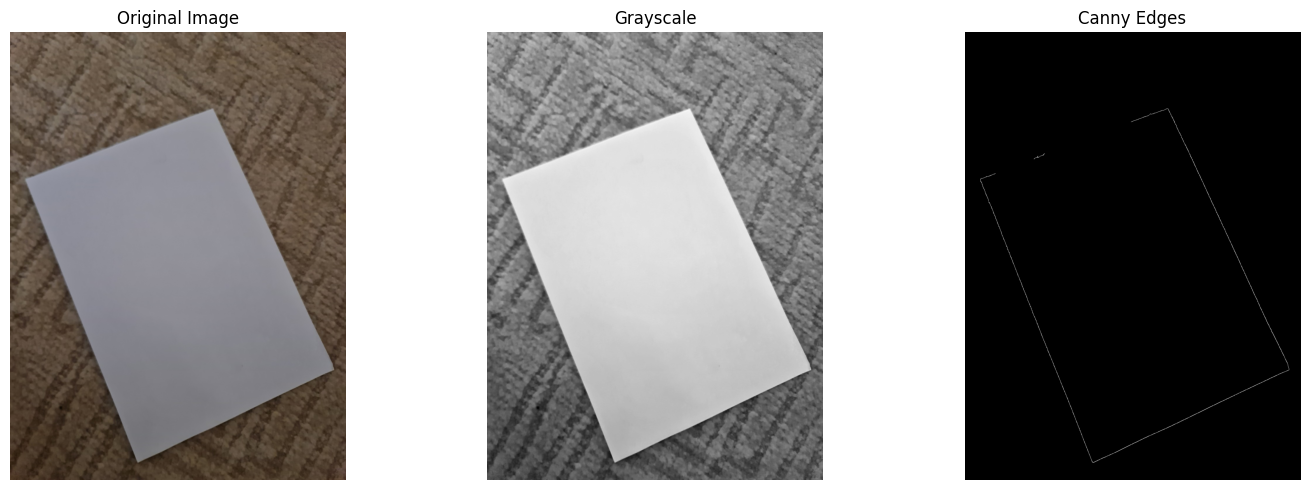

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(cv2.cvtColor(tilted_image, cv2.COLOR_BGR2RGB))
axes[0].set_title("Original Image")

axes[1].imshow(tilted_gray, cmap="gray")
axes[1].set_title("Grayscale")

axes[2].imshow(tilted_edges, cmap="gray")
axes[2].set_title("Canny Edges")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


Document Contour Detection

In [18]:
# Find external contours
document_contours, _ = cv2.findContours(tilted_edges,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)

# Sort contours by area
document_contours = sorted(document_contours,key=cv2.contourArea,reverse=True)

print("Total Contours:", len(document_contours))

Total Contours: 6


In [19]:
# Draw the 10 largest contours
contour_result = tilted_image.copy()

cv2.drawContours(contour_result,document_contours[:10],-1,(0, 0, 255),3)

array([[[ 84,  95, 115],
        [ 86,  97, 117],
        [ 87,  99, 117],
        ...,
        [ 62,  78, 101],
        [ 61,  77, 100],
        [ 59,  75,  98]],

       [[ 86,  97, 117],
        [ 86,  97, 117],
        [ 85,  97, 115],
        ...,
        [ 58,  74,  97],
        [ 59,  75,  98],
        [ 59,  75,  98]],

       [[ 88,  99, 119],
        [ 85,  96, 116],
        [ 83,  95, 113],
        ...,
        [ 60,  76,  99],
        [ 60,  76,  99],
        [ 59,  75,  98]],

       ...,

       [[ 38,  57,  78],
        [ 37,  56,  77],
        [ 41,  60,  81],
        ...,
        [ 33,  47,  70],
        [ 32,  46,  69],
        [ 32,  46,  69]],

       [[ 39,  58,  79],
        [ 36,  55,  76],
        [ 39,  58,  79],
        ...,
        [ 38,  52,  75],
        [ 40,  54,  77],
        [ 38,  52,  75]],

       [[ 45,  64,  85],
        [ 40,  59,  80],
        [ 40,  59,  80],
        ...,
        [ 36,  50,  73],
        [ 37,  51,  74],
        [ 33,  47,  70]]

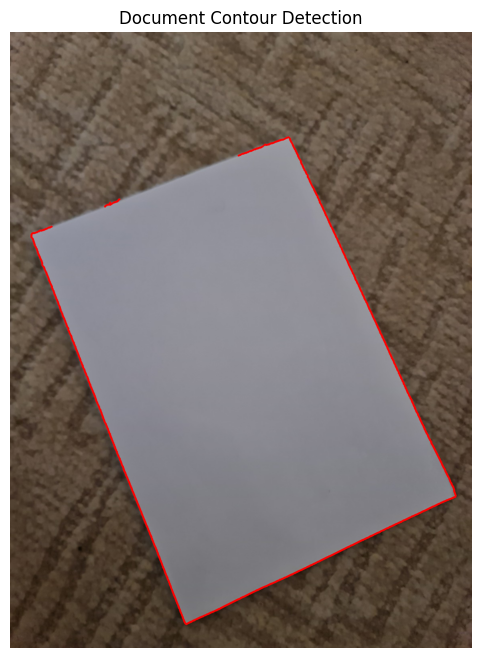

In [20]:
plt.figure(figsize=(8, 8))
plt.imshow(cv2.cvtColor(contour_result, cv2.COLOR_BGR2RGB))
plt.title("Document Contour Detection")
plt.axis("off")
plt.show()

Morphological Closing for Document Boundary Detection

In [21]:
# Create morphological kernel
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5))

In [22]:
# Connect gaps in detected edges
closed_edges = cv2.morphologyEx(tilted_edges,cv2.MORPH_CLOSE,kernel)

In [23]:
# Find external contours again
closed_contours, _ = cv2.findContours(closed_edges,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)

closed_contours = sorted(closed_contours, key=cv2.contourArea, reverse=True)

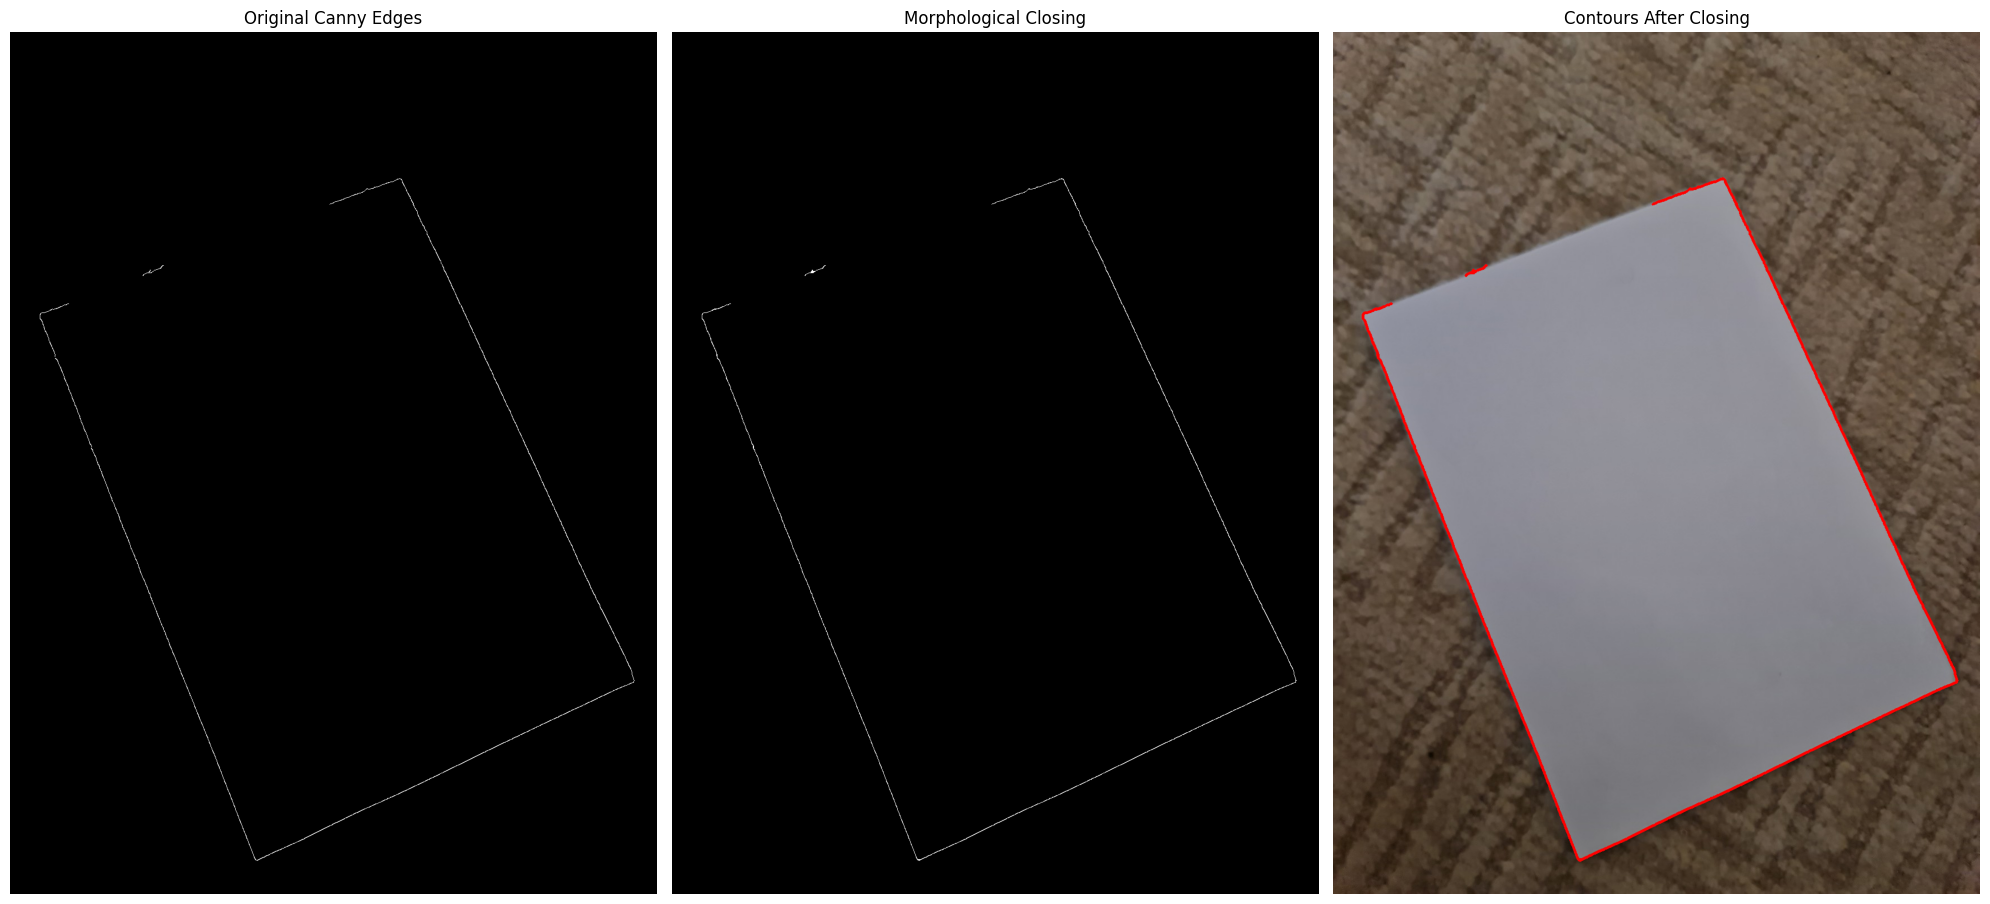

Contours After Closing: 2


In [24]:
closed_result = tilted_image.copy()

cv2.drawContours(closed_result,closed_contours[:10],-1,(0, 0, 255),4)

fig, axes = plt.subplots(1, 3, figsize=(20, 10))

axes[0].imshow(tilted_edges, cmap="gray")
axes[0].set_title("Original Canny Edges")

axes[1].imshow(closed_edges, cmap="gray")
axes[1].set_title("Morphological Closing")

axes[2].imshow(cv2.cvtColor(closed_result, cv2.COLOR_BGR2RGB))
axes[2].set_title("Contours After Closing")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Contours After Closing:", len(closed_contours))


Four-Corner Detection

In [25]:
document_corners = None
corner_result = tilted_image.copy()

image_area = tilted_image.shape[0] * tilted_image.shape[1]

for contour in closed_contours:
    area = cv2.contourArea(contour)

    if area < 0.15 * image_area:
        continue

    perimeter = cv2.arcLength(contour, True)

    for factor in [0.01, 0.02, 0.03, 0.04, 0.05]:

        approx = cv2.approxPolyDP(contour,factor * perimeter,True)

        print(f"Epsilon {factor}: {len(approx)} corners")

        if len(approx) == 4 and cv2.isContourConvex(approx):
            document_corners = approx
            break

    if document_corners is not None:
        break

No valid document contour found.


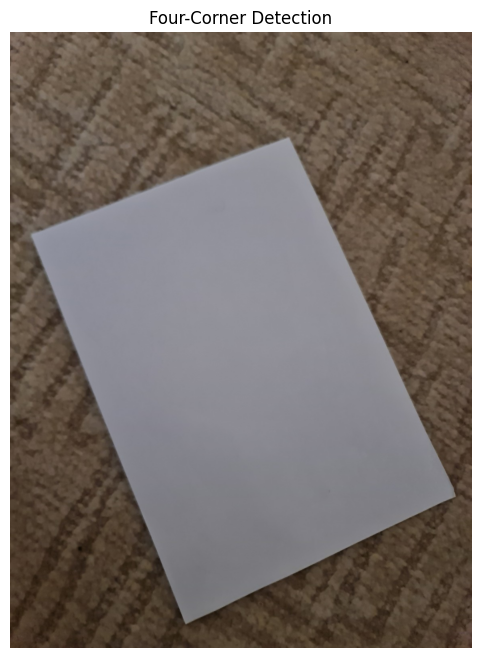

In [26]:
# Visualize 
if document_corners is not None:

    cv2.drawContours(corner_result,[document_corners],-1,(0, 255, 0), 4 )

    for point in document_corners.reshape(4, 2):
        x, y = point

        cv2.circle(corner_result,(int(x), int(y)),9,(0, 0, 255),-1)

    print("Document corners detected!")
    print(document_corners.reshape(4, 2))

else:
    print("No valid document contour found.")

plt.figure(figsize=(8, 8))
plt.imshow(cv2.cvtColor(corner_result, cv2.COLOR_BGR2RGB))
plt.title("Four-Corner Detection")
plt.axis("off")
plt.show()


Document Segmentation Using Otsu Thresholding


In [27]:
# Apply Otsu Thresholding
otsu_value, binary = cv2.threshold(tilted_blurred,0,255,cv2.THRESH_BINARY + cv2.THRESH_OTSU)

In [28]:
# Apply Morphological Closing
kernel = cv2.getStructuringElement(cv2.MORPH_RECT,(7, 7))

binary_closed = cv2.morphologyEx(binary,cv2.MORPH_CLOSE,kernel)

In [29]:
# Find external contours
seg_contours, _ = cv2.findContours(binary_closed,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)

seg_contours = sorted(seg_contours,key=cv2.contourArea,reverse=True)

Visualize segmentation

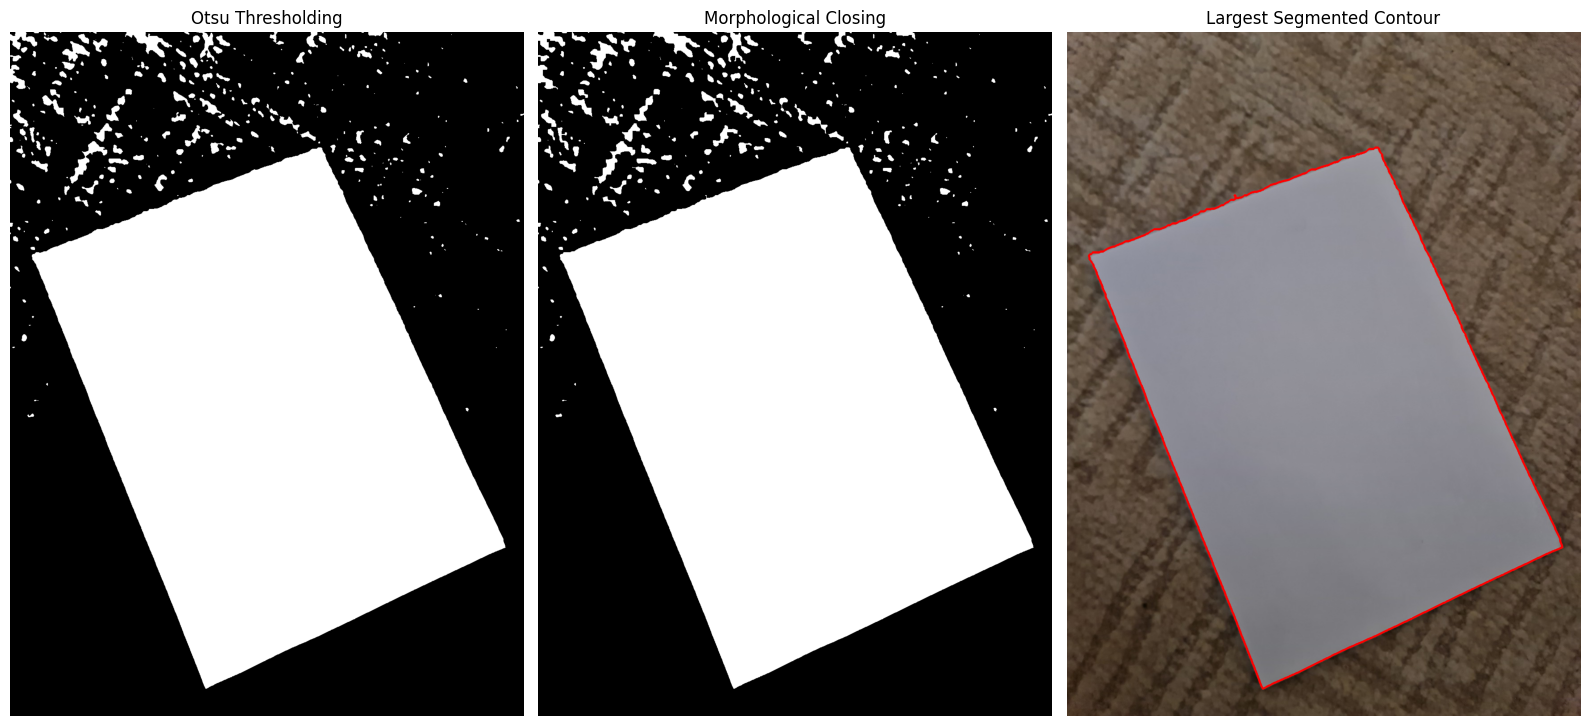

Otsu Threshold: 107.0
Total Contours: 281
Largest Contour Area: 730200.5


In [30]:
seg_result = tilted_image.copy()

if seg_contours:
    cv2.drawContours(seg_result,[seg_contours[0]],-1,(0, 0, 255),4)

fig, axes = plt.subplots(1, 3, figsize=(16, 10))

axes[0].imshow(binary, cmap="gray")
axes[0].set_title("Otsu Thresholding")

axes[1].imshow(binary_closed, cmap="gray")
axes[1].set_title("Morphological Closing")

axes[2].imshow(cv2.cvtColor(seg_result, cv2.COLOR_BGR2RGB))
axes[2].set_title("Largest Segmented Contour")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Otsu Threshold:", otsu_value)
print("Total Contours:", len(seg_contours))

if seg_contours:
    print("Largest Contour Area:", cv2.contourArea(seg_contours[0]))


Four-Corner Detection After Otsu Segmentation

In [31]:
# Select largest contour
largest_contour = seg_contours[0]

# Calculate perimeter
perimeter = cv2.arcLength(largest_contour, True)

# Approximate contour
epsilon = 0.02 * perimeter

document_corners = cv2.approxPolyDP(largest_contour, epsilon,True)

print("Number of Corners:", len(document_corners))
print("Corner Coordinates:")
print(document_corners.reshape(-1, 2))


Number of Corners: 4
Corner Coordinates:
[[ 697  261]
 [  49  502]
 [ 438 1474]
 [1110 1157]]


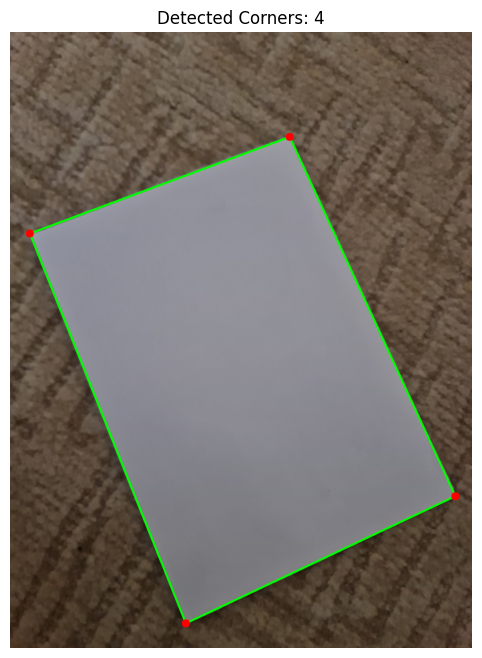

In [32]:
# Draw detected corners
corner_result = tilted_image.copy()

cv2.drawContours(corner_result,[document_corners],-1,(0, 255, 0),4)

for point in document_corners.reshape(-1, 2):
    x, y = point

    cv2.circle(corner_result,(int(x), int(y)),10,(0, 0, 255),-1)

plt.figure(figsize=(8, 8))
plt.imshow(cv2.cvtColor(corner_result, cv2.COLOR_BGR2RGB))
plt.title(f"Detected Corners: {len(document_corners)}")
plt.axis("off")
plt.show()

# Ordering Corners and Applying Perspective Transform

In [33]:
def order_points(pts):
    """
    top-left, top-right, bottom-right, bottom-left
    """
    pts = np.array(pts, dtype="float32")

    # Sum of coordinates
    s = pts.sum(axis=1)
    
    # Difference between coordinates
    diff = np.diff(pts, axis=1)

    top_left = pts[np.argmin(s)]
    bottom_right = pts[np.argmax(s)]
    top_right = pts[np.argmin(diff)]
    bottom_left = pts[np.argmax(diff)]

    return np.array([top_left, top_right, bottom_right, bottom_left], dtype="float32")


Points Corners:
Top-Left: [ 49. 502.]
Top-Right: [697. 261.]
Bottom-Right: [1110. 1157.]
Bottom-Left: [ 438. 1474.]


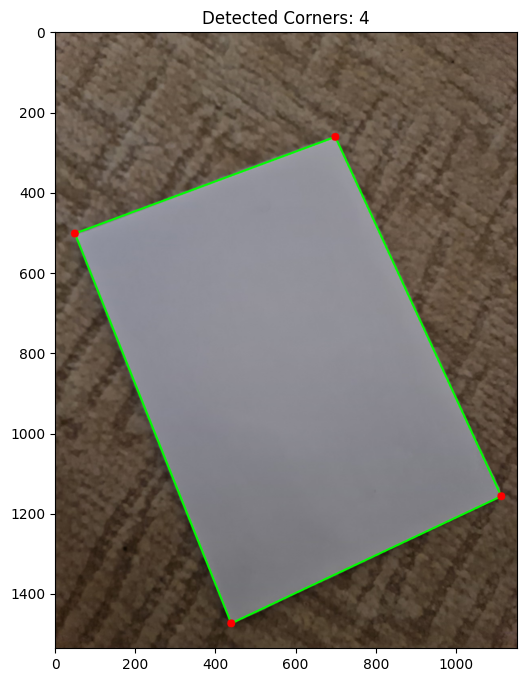

In [34]:
pts = document_corners.reshape(4, 2)

rect = order_points(pts)
(tl, tr, br, bl) = rect

print("Points Corners:")
print("Top-Left:", tl)
print("Top-Right:", tr)
print("Bottom-Right:", br)
print("Bottom-Left:", bl)

plt.figure(figsize=(8, 8))
plt.imshow(cv2.cvtColor(corner_result, cv2.COLOR_BGR2RGB))
plt.title(f"Detected Corners: {len(document_corners)}")
plt.show()

In [35]:
#  width of the new image
widthA = np.linalg.norm(br - bl)
widthB = np.linalg.norm(tr - tl)
maxWidth = int(max(widthA, widthB))

#  height of the new image
heightA = np.linalg.norm(tr - br)
heightB = np.linalg.norm(tl - bl)
maxHeight = int(max(heightA, heightB))

# Destination points
destination = np.array([
    [0, 0],
    [maxWidth - 1, 0],
    [maxWidth - 1, maxHeight - 1],
    [0, maxHeight - 1]
], dtype="float32")


In [36]:
# Get perspective transform matrix
matrix = cv2.getPerspectiveTransform(rect, destination)

# Apply warp perspective
warped = cv2.warpPerspective(tilted_image, matrix, (maxWidth, maxHeight))

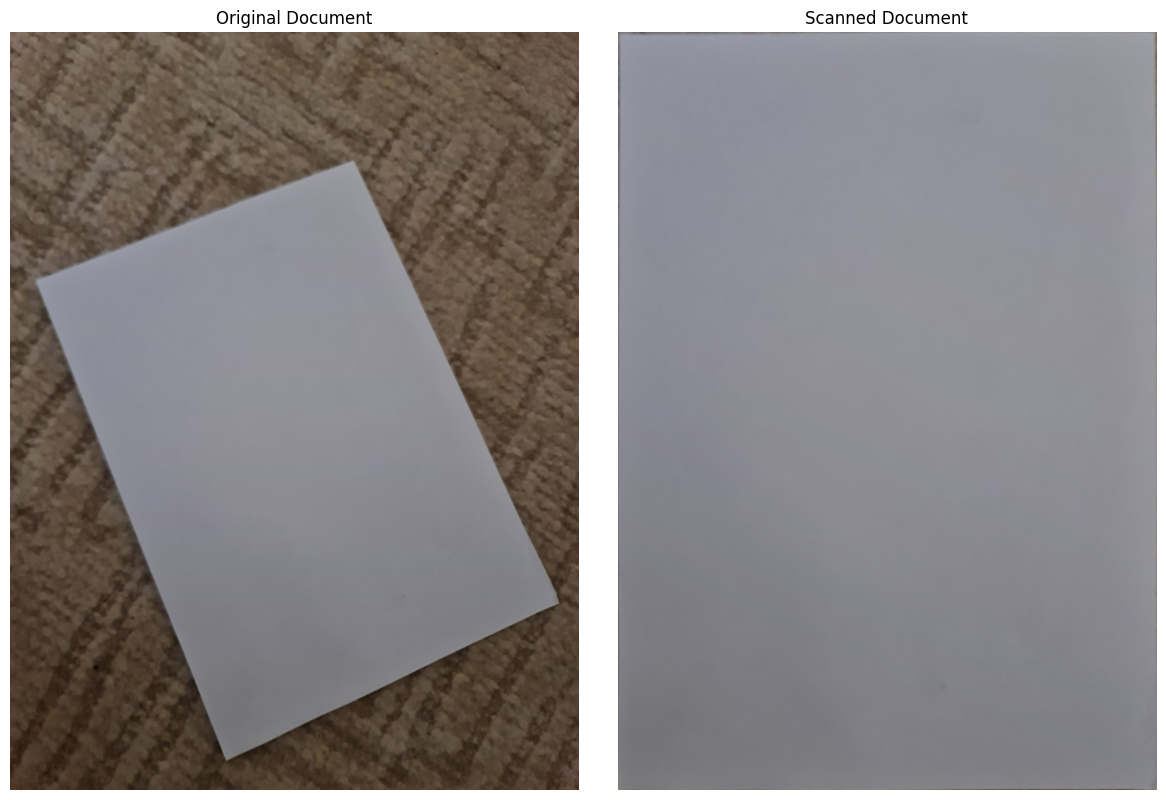

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(12, 8))

axes[0].imshow(cv2.cvtColor(tilted_image, cv2.COLOR_BGR2RGB))
axes[0].set_title("Original Document")
axes[0].axis("off")

axes[1].imshow(cv2.cvtColor(warped, cv2.COLOR_BGR2RGB))
axes[1].set_title("Scanned Document")
axes[1].axis("off")

plt.tight_layout()
plt.show()

Scanned Document Enhancement

In [38]:
# Convert warped document to grayscale
warped_gray = cv2.cvtColor(warped,cv2.COLOR_BGR2GRAY)

# Improve local contrast using CLAHE
clahe = cv2.createCLAHE(clipLimit=2.0,tileGridSize=(8, 8))

enhanced_gray = clahe.apply(warped_gray)

# Apply Adaptive Thresholding
scanned_binary = cv2.adaptiveThreshold(
    enhanced_gray,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    31,
    10
)

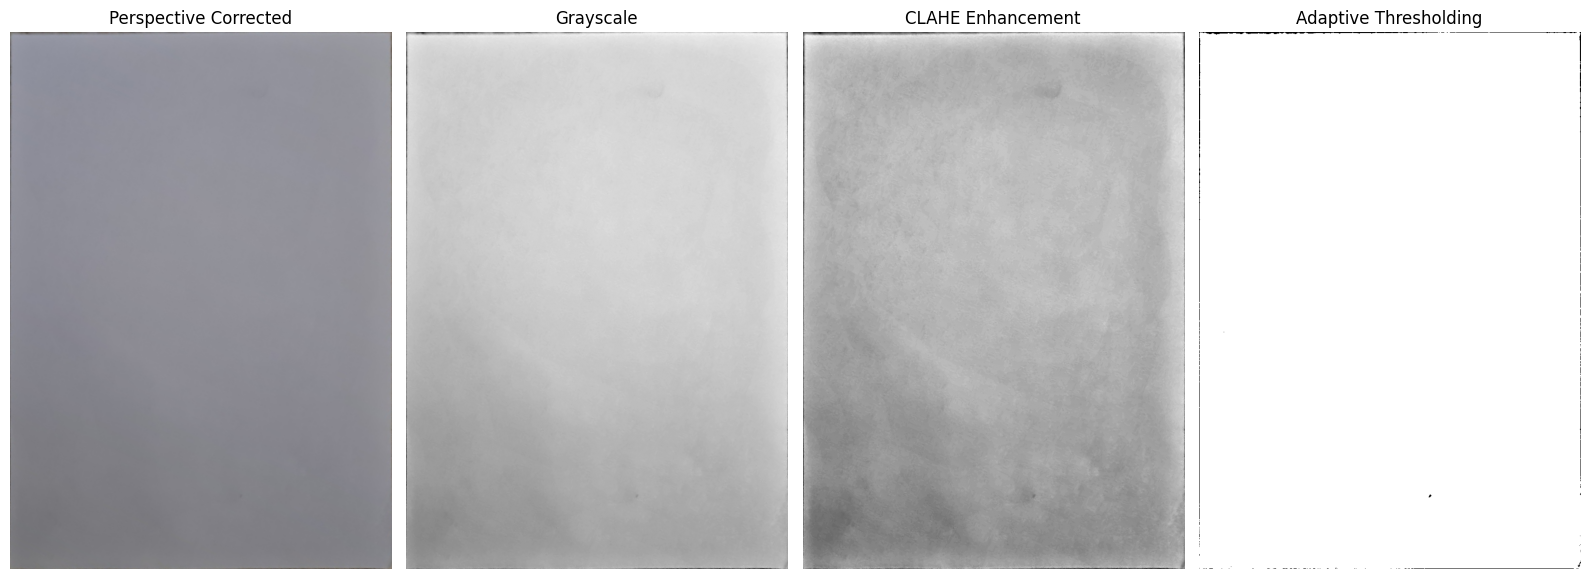

In [39]:
fig, axes = plt.subplots(1, 4, figsize=(16, 8))

images = [
    cv2.cvtColor(warped, cv2.COLOR_BGR2RGB),
    warped_gray,
    enhanced_gray,
    scanned_binary
]

titles = [
    "Perspective Corrected",
    "Grayscale",
    "CLAHE Enhancement",
    "Adaptive Thresholding"
]

for i, ax in enumerate(axes):
    ax.imshow(images[i],cmap="gray" if i > 0 else None)
    ax.set_title(titles[i])
    ax.axis("off")

plt.tight_layout()
plt.show()


# Image Enhancement on Text Documents

In [40]:
text_document = image.copy()

# Convert to grayscale
text_gray = cv2.cvtColor(text_document,cv2.COLOR_BGR2GRAY)

# Apply CLAHE
clahe = cv2.createCLAHE(clipLimit=2.0,tileGridSize=(8, 8))

text_clahe = clahe.apply(text_gray)

# Apply Adaptive Thresholding
text_binary = cv2.adaptiveThreshold(
    text_clahe,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    31,
    10
)

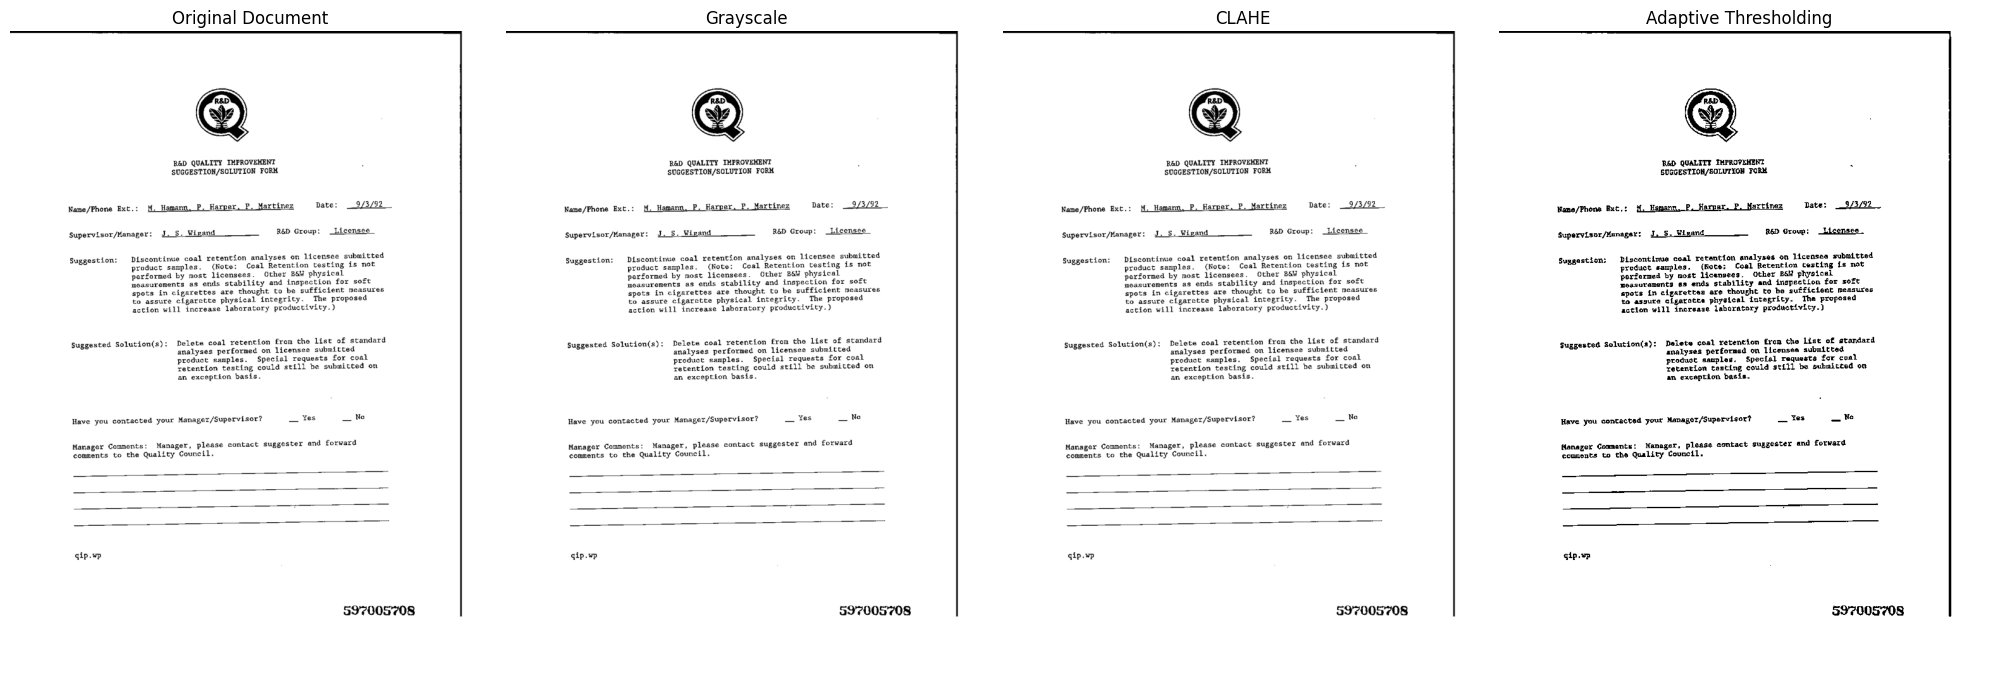

In [41]:
fig, axes = plt.subplots(1, 4, figsize=(20, 7))

images = [
    cv2.cvtColor(text_document, cv2.COLOR_BGR2RGB),
    text_gray,
    text_clahe,
    text_binary
]

titles = [
    "Original Document",
    "Grayscale",
    "CLAHE",
    "Adaptive Thresholding"
]

for i, ax in enumerate(axes):
    ax.imshow(
        images[i],
        cmap="gray" if i > 0 else None
    )
    ax.set_title(titles[i])
    ax.axis("off")

plt.tight_layout()
plt.show()


# Text Extraction Using PaddleOCR

Initialize the PaddleOCR engine and extract text from a FUNSD document using text detection and recognition.

In [ ]:
ocr = PaddleOCR(
    lang="en",
    device="cpu",
    use_doc_orientation_classify=False,
    use_doc_unwarping=False,
    use_textline_orientation=False
)

Creating model: ('PP-OCRv6_medium_det', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\MaenQawasmeh\.paddlex\official_models\PP-OCRv6_medium_det`.
Creating model: ('PP-OCRv6_medium_rec', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\MaenQawasmeh\.paddlex\official_models\PP-OCRv6_medium_rec`.


{'res': {'input_path': 'dataset\\training_data\\images\\0000971160.png', 'page_index': None, 'model_settings': {'use_doc_preprocessor': False, 'use_textline_orientation': False}, 'dt_polys': array([[[321, 104],
        ...,
        [321, 116]],

       ...,

       [[525, 906],
        ...,
        [525, 926]]], shape=(28, 4, 2), dtype=int16), 'text_det_params': {'limit_side_len': 64, 'limit_type': 'min', 'thresh': 0.3, 'max_side_limit': 4000, 'box_thresh': 0.6, 'unclip_ratio': 1.5}, 'text_type': 'general', 'textline_orientation_angles': array([-1, ..., -1], shape=(28,)), 'text_rec_score_thresh': 0.0, 'return_word_box': False, 'rec_texts': ['R&D', 'R&D QUALITY IMPROVEMENT', 'SUGGESTION/SOLUTION FORM', 'Name/Phone Ext.: M. Hamann, P. Harper, P. Martinez', 'Date:', '9/3/92', 'Supervisor/Manager: J. S. Wigand', 'R&D Group: Licensee', 'Suggestion:', 'Discontinue coal retention analyses on licensee submitted', 'product samples. (Note: Coal Retention testing is not', 'performed by most licen

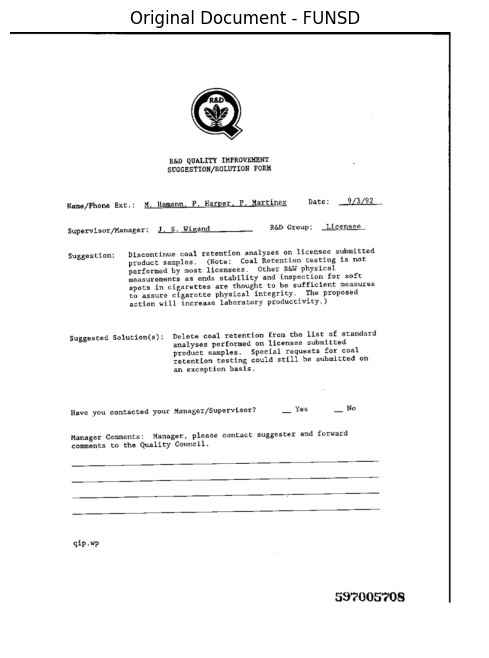

In [51]:
# Run OCR on the original FUNSD document
ocr_results = ocr.predict(str(image_path))

# Display extracted results
for result in ocr_results:
    result.print()

# Display document
plt.figure(figsize=(10, 8))
plt.imshow(image_rgb)
plt.title("Original Document - FUNSD")
plt.axis("off")
plt.show()

Extracting OCR Text and Confidence Scores


In [53]:
# Get first prediction result
result = ocr_results[0]

# Extract recognized texts and confidence scores
texts = result["rec_texts"]
scores = result["rec_scores"]

# Create DataFrame
ocr_df = pd.DataFrame({"Text": texts,"Confidence": scores})

# Display OCR results
display(ocr_df)

# Calculate statistics
print("Total Detected Texts:", len(ocr_df))
print("Average Confidence:", round(ocr_df["Confidence"].mean(), 4))
print("Minimum Confidence:", round(ocr_df["Confidence"].min(), 4))
print("Maximum Confidence:", round(ocr_df["Confidence"].max(), 4))


,Text,Confidence
0,R&D,0.999955
1,R&D QUALITY IMPROVEMENT,0.976899
2,SUGGESTION/SOLUTION FORM,0.999675
3,"Name/Phone Ext.: M. Hamann, P. Harper, P. Mart...",0.978430
4,Date:,0.999544
5,9/3/92,0.999973
6,Supervisor/Manager: J. S. Wigand,0.996601
7,R&D Group: Licensee,0.975763
8,Suggestion:,0.999953
9,Discontinue coal retention analyses on license...,0.999592


Total Detected Texts: 28
Average Confidence: 0.9941
Minimum Confidence: 0.9541
Maximum Confidence: 1.0


# OCR Performance Comparison Across Preprocessing Techniques

In [57]:
image_variants = {
    "Original": text_document,
    "Grayscale": text_gray,
    "CLAHE": text_clahe,
    "Adaptive Thresholding": text_binary
}

In [58]:
comparison_results = []
ocr_predictions = {}

for name, img in image_variants.items():

    # Convert grayscale images to 3-channel BGR
    if img.ndim == 2:
        ocr_input = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
    else:
        ocr_input = img.copy()

    print(f"Processing: {name} | Shape: {ocr_input.shape}")

    # Run OCR
    predictions = ocr.predict(ocr_input)
    result = predictions[0]

    # Save predictions
    ocr_predictions[name] = result

    texts = result["rec_texts"]
    scores = np.asarray(result["rec_scores"])

    comparison_results.append({
        "Method": name,
        "Detected Texts": len(texts),
        "Average Confidence": (
            float(scores.mean()) if len(scores) else 0.0
        ),
        "Minimum Confidence": (
            float(scores.min()) if len(scores) else 0.0
        )
    })


Processing: Original | Shape: (1000, 762, 3)
Processing: Grayscale | Shape: (1000, 762, 3)
Processing: CLAHE | Shape: (1000, 762, 3)
Processing: Adaptive Thresholding | Shape: (1000, 762, 3)


In [59]:
# comparison DataFrame
comparison_df = pd.DataFrame(comparison_results)

display(comparison_df)


,Method,Detected Texts,Average Confidence,Minimum Confidence
0,Original,28,0.994064,0.954105
1,Grayscale,28,0.994064,0.954105
2,CLAHE,28,0.994318,0.955088
3,Adaptive Thresholding,28,0.963529,0.779355


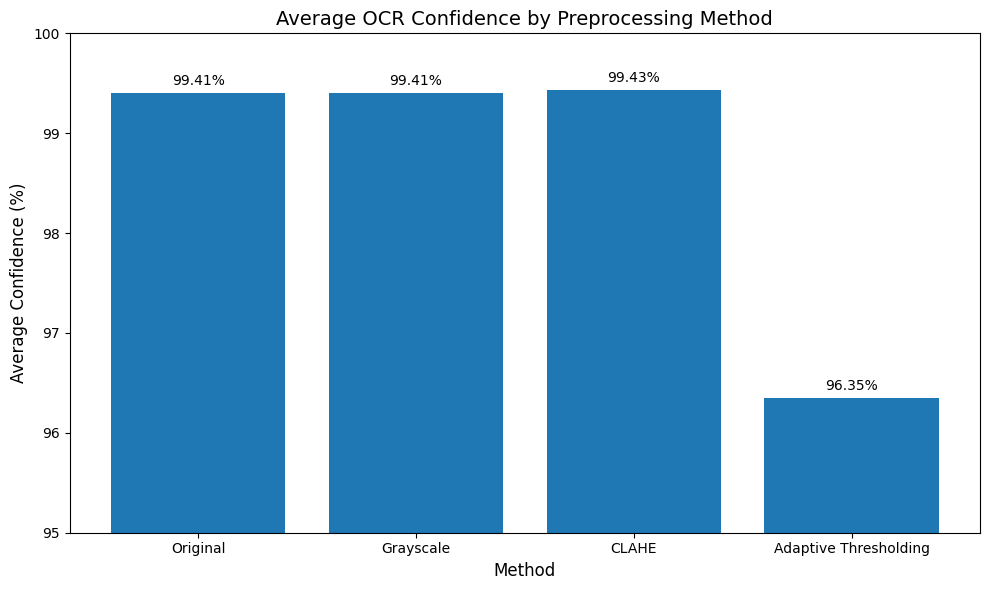

In [ ]:
methods = comparison_df["Method"]
avg_conf = comparison_df["Average Confidence"] * 100  

plt.figure(figsize=(10, 6))
bars = plt.bar(methods, avg_conf)

plt.title("Average OCR Confidence by Preprocessing Method", fontsize=14)
plt.ylabel("Average Confidence (%)", fontsize=12)
plt.xlabel("Method", fontsize=12)

plt.ylim(95, 100)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.05,
        f"{height:.2f}%",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.tight_layout()
plt.show()

# Comparing Recognized Text Across Preprocessing Methods

Compare recognized text from different preprocessing techniques to identify recognition differences and evaluate their impact before calculating CER and WER.

In [68]:
# Extract recognized text from each method
recognized_texts = {
    name: list(result["rec_texts"])
    for name, result in ocr_predictions.items()
}

In [ ]:
# Compare each method with the original
original_texts = recognized_texts["Original"]

for method, texts in recognized_texts.items():

    if method == "Original":
        continue

    print(f"\n{'=' * 50}")
    print(f"Original vs {method}")
    print(f"{'=' * 50}")

    # Compare only when the number of segments matches
    if len(original_texts) != len(texts):
        print("Different number of text segments.")
        print("Manual alignment is required.")
        continue

    differences = 0

    for i, (original, processed) in enumerate(
        zip(original_texts, texts)
    ):

        if original != processed:
            differences += 1

            print(f"\nSegment {i + 1}")
            print("Original :", original)
            print("Processed:", processed)

    print(f"\nDifferent segments: {differences}")


Original vs Grayscale

Different segments: 0

Original vs CLAHE

Different segments: 0

Original vs Adaptive Thresholding

Segment 1
Original : R&D
Processed: RAD

Segment 2
Original : R&D QUALITY IMPROVEMENT
Processed: R&D QUALITT IHPROVEHENT

Segment 3
Original : SUGGESTION/SOLUTION FORM
Processed: SUGGESTION/SOLUTYON FORK

Segment 4
Original : Name/Phone Ext.: M. Hamann, P. Harper, P. Martinez
Processed: Name/Phona Ext,: M. Hamann. P. Harpar. P. Martinez

Segment 7
Original : Supervisor/Manager: J. S. Wigand
Processed: Supervisor/Hanager: J. S. Wigand

Segment 9
Original : Suggestion:
Processed: Suggastion;

Segment 12
Original : performed by most licensees. Other B&W physical
Processed: perfermed by most licensees. Other B&W physical

Segment 15
Original : to assure cigarette physical integrity. The proposed
Processed: to assure cigaratte physical integrity. The proposed

Segment 16
Original : action will increase laboratory productivity.)
Processed: actlon will increase laborator

# OCR Evaluation Using Ground Truth

## Loading Ground Truth Annotations

CER — Character Error Rate.

WER — Word Error Rate.

In [70]:
# Get annotation path corresponding to the document
annotation_path = (
    Path("dataset/training_data/annotations")
    / f"{image_path.stem}.json"
)

# Load FUNSD annotations
with open(annotation_path, "r", encoding="utf-8") as f:
    annotations = json.load(f)

# Explore annotation structure
print("Annotation Keys:", list(annotations.keys()))

print("\nTotal Form Entries:", len(annotations["form"]))

# Display first annotation
print("\nFirst Annotation:")
print(json.dumps(
    annotations["form"][0],
    indent=4,
    ensure_ascii=False
))


Annotation Keys: ['form']

Total Form Entries: 24

First Annotation:
{
    "box": [
        292,
        91,
        376,
        175
    ],
    "text": "R&D",
    "label": "other",
    "words": [
        {
            "box": [
                292,
                91,
                376,
                175
            ],
            "text": "R&D"
        }
    ],
    "linking": [],
    "id": 0
}


## Ground Truth Text Extraction


In [71]:
# Extract annotated words with their coordinates
ground_truth_words = []

for item in annotations["form"]:

    for word in item.get("words", []):

        if word.get("text", "").strip():

            ground_truth_words.append({
                "Text": word["text"],
                "Box": word["box"]
            })

# Create DataFrame
ground_truth_df = pd.DataFrame(ground_truth_words)

print("Total Ground Truth Words:", len(ground_truth_df))

display(ground_truth_df.head(20))

Total Ground Truth Words: 145


,Text,Box
0,R&D,"[292, 91, 376, 175]"
1,:,"[219, 316, 225, 327]"
2,Suggestion:,"[95, 355, 169, 370]"
3,Date:,"[482, 268, 518, 282]"
4,Licensee,"[511, 309, 570, 323]"
5,Yes,"[461, 605, 483, 619]"
6,No,"[545, 603, 563, 617]"
7,597005708,"[525, 904, 641, 926]"
8,R&D,"[257, 203, 279, 214]"
9,QUALITY,"[285, 203, 334, 216]"



## Ground Truth Reading Order Reconstruction


In [72]:
# Extract word coordinates
gt_sorted = ground_truth_df.copy()

gt_sorted["x1"] = gt_sorted["Box"].apply(lambda b: b[0])
gt_sorted["y1"] = gt_sorted["Box"].apply(lambda b: b[1])
gt_sorted["x2"] = gt_sorted["Box"].apply(lambda b: b[2])
gt_sorted["y2"] = gt_sorted["Box"].apply(lambda b: b[3])

# Calculate vertical center
gt_sorted["y_center"] = (
    gt_sorted["y1"] + gt_sorted["y2"]
) / 2

# Sort words vertically
gt_sorted = gt_sorted.sort_values(
    ["y_center", "x1"]
).reset_index(drop=True)

In [73]:
# Group words into approximate text lines
line_tolerance = 10

lines = []

for _, word in gt_sorted.iterrows():

    y = word["y_center"]

    matched_line = None

    for line in lines:
        if abs(y - line["y_center"]) <= line_tolerance:
            matched_line = line
            break

    if matched_line is None:
        lines.append({
            "y_center": y,
            "words": [word]
        })
    else:
        matched_line["words"].append(word)

        matched_line["y_center"] = (
            sum(w["y_center"] for w in matched_line["words"])
            / len(matched_line["words"])
        )

In [74]:
# Sort lines and words
lines.sort(key=lambda line: line["y_center"])

ground_truth_lines = []

for line in lines:

    sorted_words = sorted(
        line["words"],
        key=lambda w: w["x1"]
    )

    text = " ".join(
        str(w["Text"]) for w in sorted_words
    )

    ground_truth_lines.append(text)


In [75]:
# Display reconstructed text
for i, line in enumerate(ground_truth_lines, start=1):
    print(f"{i:02d}: {line}")

print("\nTotal Reconstructed Lines:", len(ground_truth_lines))

01: R&D
02: R&D QUALITY IMPROVEMENT
03: SUGGESTION/ SOLUTION FORM
04: Name / Phone Ext. : M. Hamann P. Harper, P. Martinez Date: 9/ 3/ 92
05: Supervisor / Manager : J. S. Wigand R&D Group: Licensee
06: Suggestion: Discontinue coal retention analyses on licensee submitted
07: product samples (Note : Coal Retention testing is not
08: performed by most licensees. Other B&W physical
09: measurements as ends stability and inspection for soft
10: spots in ciparettes are thought to be sufficient measures
11: to assure cigarette physical integrity. The proposed
12: action will increase laboratory productivity . )
13: Suggested Solutions (s) : Delete coal retention from the list of standard
14: analyses performed on licensee submitted
15: product samples. Special requests for coal
16: retention testing could still be submitted on
17: an exception basis.
18: Have you contacted your Manager/ Supervisor? Yes No
19: Manager Comments: Manager, please contact suggester and forward
20: comments to the

## OCR Evaluation Using CER and WER


In [81]:
# Normalize whitespace and formatting
def normalize_text(text):
    text = text.lower()
    text = re.sub(r"\s+", " ", text)
    text = re.sub(r"\s*([/:.,;!?()])\s*", r"\1", text)
    return text.strip()

# Prepare ground truth
ground_truth_text = normalize_text(
    " ".join(ground_truth_lines)
)


In [82]:
evaluation_results = []

for method, result in ocr_predictions.items():

    # Combine OCR predictions
    predicted_text = normalize_text(
        " ".join(result["rec_texts"])
    )

    # Calculate CER and WER
    cer_score = cer(ground_truth_text, predicted_text)
    wer_score = wer(ground_truth_text, predicted_text)

    evaluation_results.append({
        "Method": method,
        "CER": cer_score,
        "WER": wer_score
    })




In [83]:
# Create evaluation DataFrame
evaluation_df = pd.DataFrame(evaluation_results)

display(evaluation_df)

,Method,CER,WER
0,Original,0.004367,0.047619
1,Grayscale,0.004367,0.047619
2,CLAHE,0.004367,0.047619
3,Adaptive Thresholding,0.031659,0.228571


## Visualization of OCR Evaluation Metrics

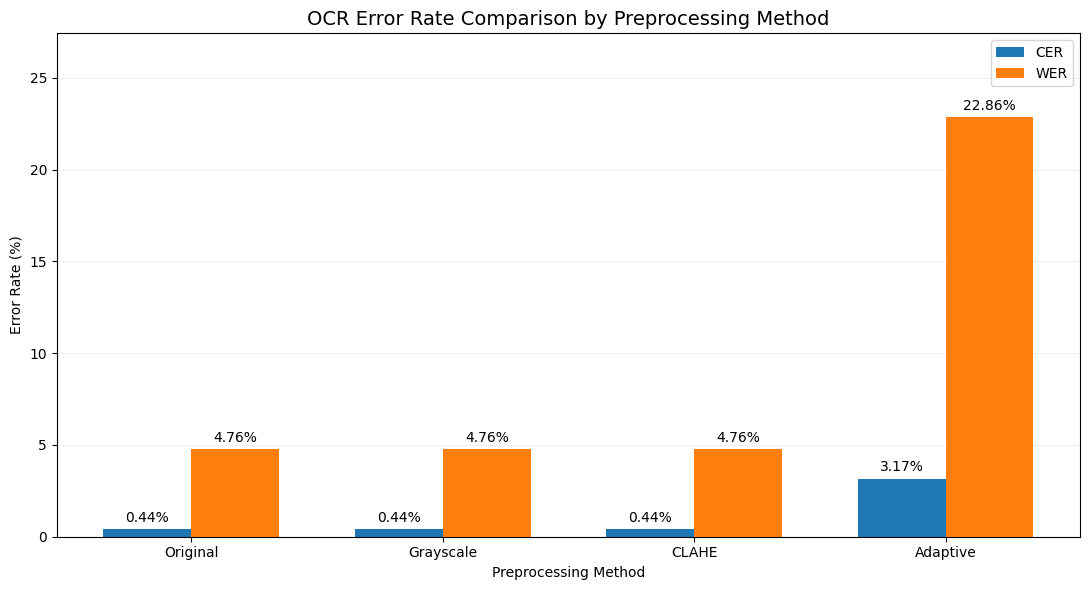

In [84]:
# Prepare data
plot_df = evaluation_df.copy()

plot_df["Method"] = plot_df["Method"].replace({
    "Adaptive Thresholding": "Adaptive"})

methods = plot_df["Method"]
cer_values = plot_df["CER"] * 100
wer_values = plot_df["WER"] * 100

x = np.arange(len(methods))
width = 0.35

# chart
fig, ax = plt.subplots(figsize=(11, 6))

bars1 = ax.bar(x - width / 2,cer_values,width,label="CER")

bars2 = ax.bar(x + width / 2,wer_values,width,label="WER")

# Labels
ax.set_title(
    "OCR Error Rate Comparison by Preprocessing Method",
    fontsize=14
)

ax.set_xlabel("Preprocessing Method")
ax.set_ylabel("Error Rate (%)")

ax.set_xticks(x)
ax.set_xticklabels(methods)

ax.legend()
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

# Display values above bars
ax.bar_label(bars1, fmt="%.2f%%", padding=3)
ax.bar_label(bars2, fmt="%.2f%%", padding=3)

ax.set_ylim(0, max(wer_values.max(), cer_values.max()) * 1.2)

plt.tight_layout()
plt.show()

## Multi-Document OCR Evaluation


In [85]:
test_images_path = Path("dataset/testing_data/images")
test_annotations_path = Path("dataset/testing_data/annotations")

test_images = sorted(test_images_path.glob("*.png"))
test_annotations = sorted(test_annotations_path.glob("*.json"))

print("Total Test Images:", len(test_images))
print("Total Annotations:", len(test_annotations))


Total Test Images: 50
Total Annotations: 50


In [87]:
# Check image-annotation matching
image_names = {p.stem for p in test_images}
annotation_names = {p.stem for p in test_annotations}

print("Images without annotations:", len(image_names - annotation_names))
print("Annotations without images:", len(annotation_names - image_names))

Images without annotations: 0
Annotations without images: 0


## Building a Reusable Ground Truth Processing Function


In [88]:

def extract_ground_truth(annotation_path, line_tolerance=10):

    with open(annotation_path, "r", encoding="utf-8") as f:
        annotations = json.load(f)

    words = []

    for item in annotations["form"]:
        for word in item.get("words", []):

            text = word.get("text", "").strip()

            if not text:
                continue

            x1, y1, x2, y2 = word["box"]

            words.append({
                "text": text,
                "x1": x1,
                "y_center": (y1 + y2) / 2
            })

    # Sort words from top to bottom
    words.sort(key=lambda w: (w["y_center"], w["x1"]))

    lines = []

    # Group words into approximate lines
    for word in words:

        matched_line = None

        for line in lines:
            if abs(word["y_center"] - line["y_center"]) <= line_tolerance:
                matched_line = line
                break

        if matched_line is None:
            lines.append({
                "y_center": word["y_center"],
                "words": [word]
            })
        else:
            matched_line["words"].append(word)

            line_words = matched_line["words"]
            matched_line["y_center"] = sum(
                w["y_center"] for w in line_words
            ) / len(line_words)

    # Sort lines and words
    lines.sort(key=lambda line: line["y_center"])

    ground_truth_lines = []

    for line in lines:

        sorted_words = sorted(
            line["words"],
            key=lambda w: w["x1"]
        )

        line_text = " ".join(
            word["text"] for word in sorted_words
        )

        ground_truth_lines.append(line_text)

    return ground_truth_lines


In [90]:
# Select first test annotation
sample_annotation = test_annotations[0]

# Extract reference lines
sample_gt_lines = extract_ground_truth(sample_annotation)

print("Annotation:", sample_annotation.name)
print("Total Lines:", len(sample_gt_lines))

print("\nFirst 10 Ground Truth Lines:")

for i, line in enumerate(sample_gt_lines[:5], start=1):
    print(f"{i:02d}: {line}")


Annotation: 82092117.json
Total Lines: 29

First 10 Ground Truth Lines:
01: ATT. GEN. ADMIN. OFFICE Fax: 614 -466 -5087 Dec 10 '98 17 :46 P. 01
02: Attorney General
03: Betty D. Montgomery
04: CONFIDENTIAL FACSIMILE
05: TRANSMISSION COVER SHEET


## Multi-Document OCR Evaluation


In [91]:
def prepare_image_variants(image):

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )

    enhanced = clahe.apply(gray)

    binary = cv2.adaptiveThreshold(enhanced,255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,cv2.THRESH_BINARY,31,10)

    return {
        "Original": image,
        "Grayscale": cv2.cvtColor(gray, cv2.COLOR_GRAY2BGR),
        "CLAHE": cv2.cvtColor(enhanced, cv2.COLOR_GRAY2BGR),
        "Adaptive Thresholding": cv2.cvtColor(
            binary, cv2.COLOR_GRAY2BGR
        )
    }


In [92]:
def evaluate_document(image_path, annotation_path):

    image = cv2.imread(str(image_path))

    if image is None:
        raise ValueError(f"Cannot read: {image_path}")

    # Prepare ground truth
    gt_lines = extract_ground_truth(annotation_path)
    gt_text = normalize_text(" ".join(gt_lines))

    # Generate image variants
    variants = prepare_image_variants(image)

    results = []

    for method, img in variants.items():

        predictions = ocr.predict(img)
        result = predictions[0]

        predicted_text = normalize_text(
            " ".join(result["rec_texts"])
        )

        results.append({
            "Image": image_path.name,
            "Method": method,
            "CER": cer(gt_text, predicted_text),
            "WER": wer(gt_text, predicted_text),
            "Detected Texts": len(result["rec_texts"])
        })

    return results


In [93]:
all_results = []

# Start with 5 test documents
for image_path in test_images[:5]:

    annotation_path = (
        test_annotations_path
        / f"{image_path.stem}.json"
    )

    print("Processing:", image_path.name)

    results = evaluate_document(
        image_path,
        annotation_path
    )

    all_results.extend(results)

# Create DataFrame
multi_eval_df = pd.DataFrame(all_results)

display(multi_eval_df)


Processing: 82092117.png
Processing: 82200067_0069.png
Processing: 82250337_0338.png
Processing: 82251504.png
Processing: 82252956_2958.png


,Image,Method,CER,WER,Detected Texts
0,82092117.png,Original,0.034536,0.198895,34
1,82092117.png,Grayscale,0.034536,0.198895,34
2,82092117.png,CLAHE,0.033768,0.193370,34
3,82092117.png,Adaptive Thresholding,0.102840,0.447514,34
4,82200067_0069.png,Original,0.121673,0.264463,61
5,82200067_0069.png,Grayscale,0.121673,0.264463,61
6,82200067_0069.png,CLAHE,0.121673,0.264463,61
7,82200067_0069.png,Adaptive Thresholding,0.181242,0.528926,58
8,82250337_0338.png,Original,0.055901,0.200000,41
9,82250337_0338.png,Grayscale,0.055901,0.200000,41


## Summary Statistics of OCR Performance


In [94]:
# Summarize OCR evaluation results
summary_df = (
    multi_eval_df
    .groupby("Method")
    .agg(
        Mean_CER=("CER", "mean"),
        Std_CER=("CER", "std"),
        Min_CER=("CER", "min"),
        Max_CER=("CER", "max"),
        Mean_WER=("WER", "mean"),
        Std_WER=("WER", "std"),
        Min_WER=("WER", "min"),
        Max_WER=("WER", "max"),
        Mean_Detected_Texts=("Detected Texts", "mean")
    )
    .reset_index()
)

# Convert error rates to percentages
metric_columns = [
    "Mean_CER", "Std_CER", "Min_CER", "Max_CER",
    "Mean_WER", "Std_WER", "Min_WER", "Max_WER"
]

summary_df[metric_columns] = summary_df[metric_columns] * 100

display(summary_df.round(2))

,Method,Mean_CER,Std_CER,Min_CER,Max_CER,Mean_WER,Std_WER,Min_WER,Max_WER,Mean_Detected_Texts
0,Adaptive Thresholding,11.69,5.30,5.62,18.12,38.58,9.92,29.14,52.89,42.4
1,CLAHE,6.13,3.62,3.27,12.17,20.65,4.39,14.61,26.45,45.2
2,Grayscale,6.14,3.61,3.27,12.17,20.76,4.36,14.61,26.45,45.2
3,Original,6.14,3.61,3.27,12.17,20.76,4.36,14.61,26.45,45.2


## OCR Error Analysis


In [96]:
# Select document for error analysis
sample_name = "82200067_0069"

image_path_eval = test_images_path / f"{sample_name}.png"
annotation_path_eval = test_annotations_path / f"{sample_name}.json"

# Load reference text
gt_lines = extract_ground_truth(annotation_path_eval)

# Run OCR on original image
original_eval_image = cv2.imread(str(image_path_eval))

if original_eval_image is None:
    raise FileNotFoundError(image_path_eval)

prediction = ocr.predict(original_eval_image)[0]

# Prepare lines
reference_lines = [
    normalize_text(line) for line in gt_lines
]

predicted_lines = [
    normalize_text(line) for line in prediction["rec_texts"]
]

# Display differences
diff = unified_diff(
    reference_lines,
    predicted_lines,
    fromfile="Ground Truth",
    tofile="PaddleOCR",
    lineterm=""
)

print("\n".join(diff))


--- Ground Truth
+++ PaddleOCR
@@ -1,24 +1,61 @@
-09/17/97 10:55 603 841 1898 lorillard ptld ☑ 001
-to:k.a.sparrow
-from:t.d.blachly may 12 aug 4
-jun 23 sep 15 x
-subject:old gold menthol lights & ultra lights 100's progress report
+09/17/97
+10:55
+503 641 1898
+lorillard ptld
+001
+to:
+k.a.sparrow
+from:
+t.d.blachly
+may 12
+aug 4
+jun 23
+sep 15
+x
+subject:
+old gold menthol lights & ultra lights 1oo's - progress beport
 region:
 (only if partial region continue with division(s)scope)
 division:
-division:portland # reps:6 division:seattle south # reps:7
-division:boise # reps:2.5 division:seattle north # reps:4
-division:eugene # reps:5 division:helena # reps:4
+division:portland
+#reps:6
+division:seattle south
+# reps:7
+division:
+boise
+# reps:2.5
+division:seattle north
+#reps:4
+division:
+eugene
+# reps:5
+division:helena
+# reps:4
 direct accounts and chains headquartered within the region
-(15 + stores)stocking no old gold menthol lights or ultra lights 100's
-no.of no

## Visualizing Ground Truth and OCR Bounding Boxes


In [97]:
# Load document and annotations
image_vis = cv2.imread(str(image_path_eval))

with open(annotation_path_eval, "r", encoding="utf-8") as f:
    gt_annotations = json.load(f)

In [107]:
# Draw ground truth word boxes
gt_vis = image_vis.copy()

for item in gt_annotations["form"]:
    for word in item.get("words", []):
        x1, y1, x2, y2 = word["box"]

        cv2.rectangle(
            gt_vis,
            (x1, y1),
            (x2, y2),
            (0, 0, 255),
            2
        )


In [102]:
# Draw PaddleOCR recognized text polygons
ocr_vis = image_vis.copy()

for poly in prediction["rec_polys"]:
    points = np.asarray(poly, dtype=np.int32)

    cv2.polylines(
        ocr_vis,
        [points],
        isClosed=True,
        color=(0, 0, 255),
        thickness=2
    )


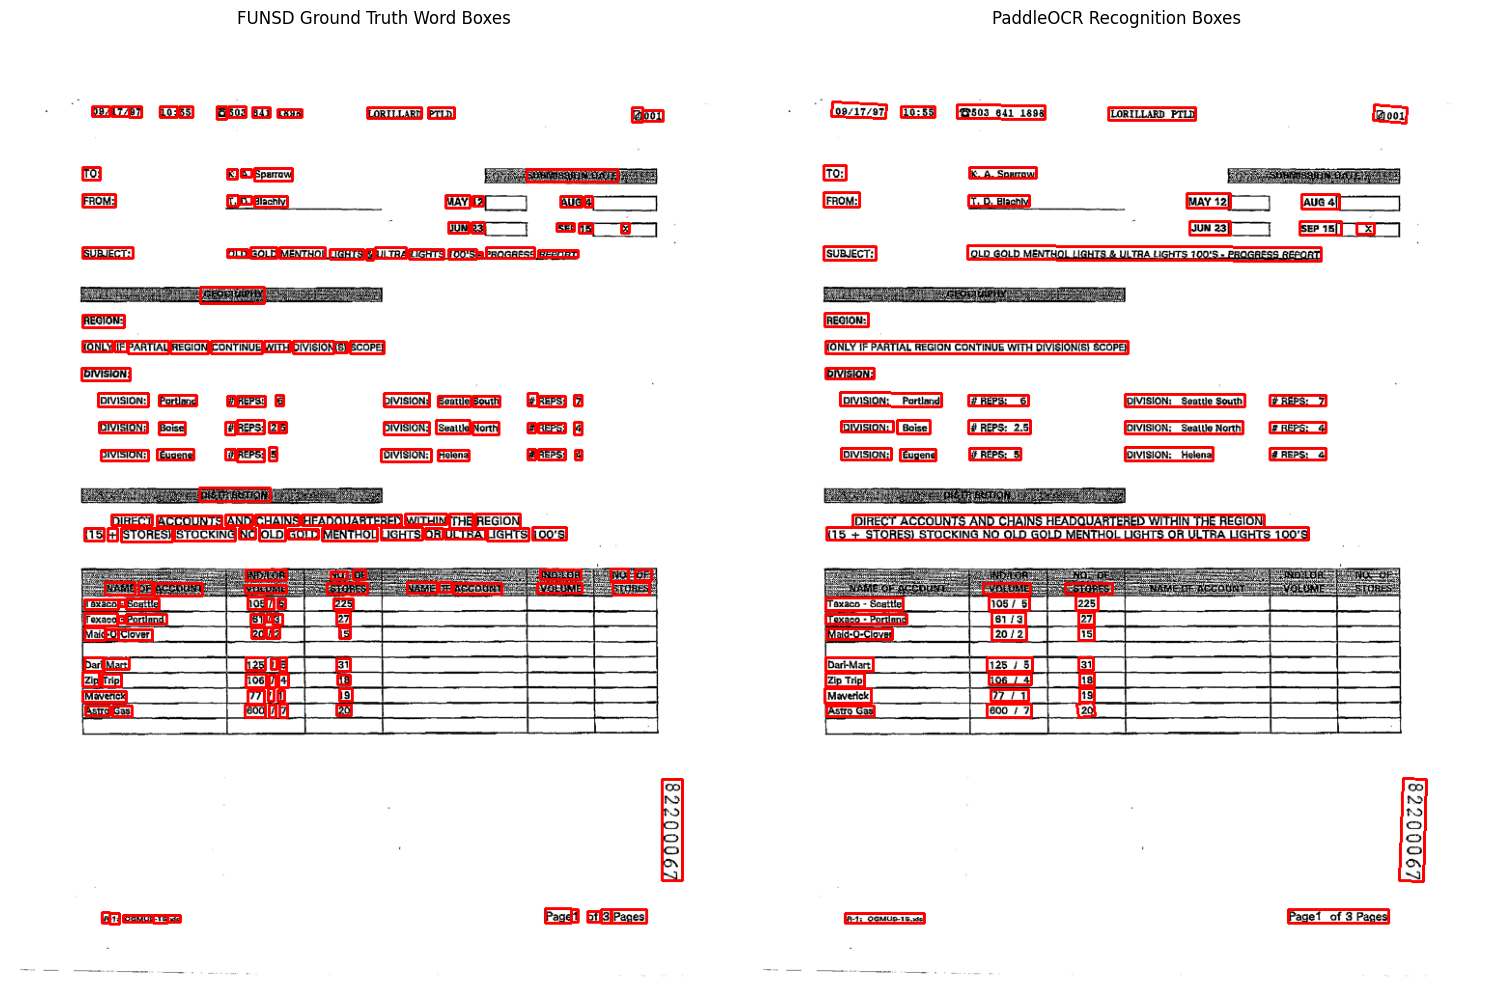

In [108]:
# visualization
fig, axes = plt.subplots(1, 2, figsize=(15, 10))

axes[0].imshow(cv2.cvtColor(gt_vis, cv2.COLOR_BGR2RGB))
axes[0].set_title("FUNSD Ground Truth Word Boxes")

axes[1].imshow(cv2.cvtColor(ocr_vis, cv2.COLOR_BGR2RGB))
axes[1].set_title("PaddleOCR Recognition Boxes")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

## Spatial Matching Between Ground Truth and PaddleOCR


Match ground truth words with recognized OCR regions based on their bounding box positions to examine text detection coverage independently of reading order.

In [ ]:
def intersection_ratio(gt_box, ocr_box):
    """
    Compute intersection area relative to
    the ground truth word box area.
    """
    gx1, gy1, gx2, gy2 = gt_box
    ox1, oy1, ox2, oy2 = ocr_box

    ix1 = max(gx1, ox1)
    iy1 = max(gy1, oy1)
    ix2 = min(gx2, ox2)
    iy2 = min(gy2, oy2)

    intersection = max(0, ix2 - ix1) * max(0, iy2 - iy1)
    gt_area = max(1, (gx2 - gx1) * (gy2 - gy1))

    return intersection / gt_area

In [110]:
# Extract Ground Truth words
gt_words = []

for item in gt_annotations["form"]:
    for word in item.get("words", []):
        if word.get("text", "").strip():
            gt_words.append(word)

In [111]:
# OCR bounding boxes and recognized text
ocr_boxes = prediction["rec_boxes"]
ocr_texts = prediction["rec_texts"]

matched_results = []

for word in gt_words:

    gt_box = word["box"]

    best_score = 0
    best_text = None

    for box, text in zip(ocr_boxes, ocr_texts):

        score = intersection_ratio(gt_box, box)

        if score > best_score:
            best_score = score
            best_text = text

    matched_results.append({
        "Ground Truth": word["text"],
        "Matched OCR Region": best_text,
        "Overlap Ratio": best_score,
        "Spatially Matched": best_score >= 0.5
    })


In [113]:
spatial_df = pd.DataFrame(matched_results)

display(spatial_df.head(50))

print(
    "Spatial Match Rate:",
    round(spatial_df["Spatially Matched"].mean() * 100, 2),
    "%"
)

,Ground Truth,Matched OCR Region,Overlap Ratio,Spatially Matched
0,TO:,TO:,1.000000,True
1,FROM:,FROM:,1.000000,True
2,x,x,1.000000,True
3,SUBJECT:,SUBJECT:,1.000000,True
4,DIVISION:,DIVISION:,0.829231,True
5,DIVISION:,DIVISION: Portland,1.000000,True
6,DIVISION:,DIVISION:,0.909091,True
7,DIVISION:,DIVISION:,0.909091,True
8,REGION:,REGION:,0.923077,True
9,DIVISION:,DIVISION: Seattle South,0.928571,True


Spatial Match Rate: 92.81 %



## Spatial Coverage Analysis



Evaluate the coverage of FUNSD ground truth word boxes by PaddleOCR recognition regions using different overlap thresholds, and inspect unmatched words.


In [ ]:
# Calculate spatial coverage at different thresholds
thresholds = [0.25, 0.50, 0.75, 0.90]

coverage_results = []

for threshold in thresholds:

    matched = (
        spatial_df["Overlap Ratio"] >= threshold
    ).sum()

    total = len(spatial_df)

    coverage_results.append({
        "Threshold": threshold,
        "Matched Words": matched,
        "Total GT Words": total,
        "Coverage (%)": matched / total * 100
    })

In [115]:
coverage_df = pd.DataFrame(coverage_results)

display(coverage_df.round(2))

# Inspect words with insufficient coverage
unmatched_words = spatial_df[
    spatial_df["Overlap Ratio"] < 0.50
]

print("Unmatched GT Words:", len(unmatched_words))

display(unmatched_words)

,Threshold,Matched Words,Total GT Words,Coverage (%)
0,0.25,155,167,92.81
1,0.50,155,167,92.81
2,0.75,155,167,92.81
3,0.90,138,167,82.63


Unmatched GT Words: 12


,Ground Truth,Matched OCR Region,Overlap Ratio,Spatially Matched
113,NAME,None,0.0,False
114,OF,None,0.0,False
115,ACCOUNT,None,0.0,False
117,NO.,None,0.0,False
118,OF,None,0.0,False
120,NAME,None,0.0,False
121,OF,None,0.0,False
122,ACCOUNT,None,0.0,False
123,VOLUME,None,0.0,False
124,NO.,None,0.0,False


## Visualizing Unmatched Ground Truth Words


In [116]:
# Collect ground truth word boxes in the same order
gt_word_boxes = []

for item in gt_annotations["form"]:
    for word in item.get("words", []):
        if word.get("text", "").strip():
            gt_word_boxes.append(word["box"])

# Copy document image
unmatched_vis = image_vis.copy()

# Draw unmatched words
for i, row in spatial_df.iterrows():

    if row["Overlap Ratio"] >= 0.50:
        continue

    x1, y1, x2, y2 = gt_word_boxes[i]

    cv2.rectangle(
        unmatched_vis,
        (x1, y1),
        (x2, y2),
        (0, 0, 255),
        2
    )

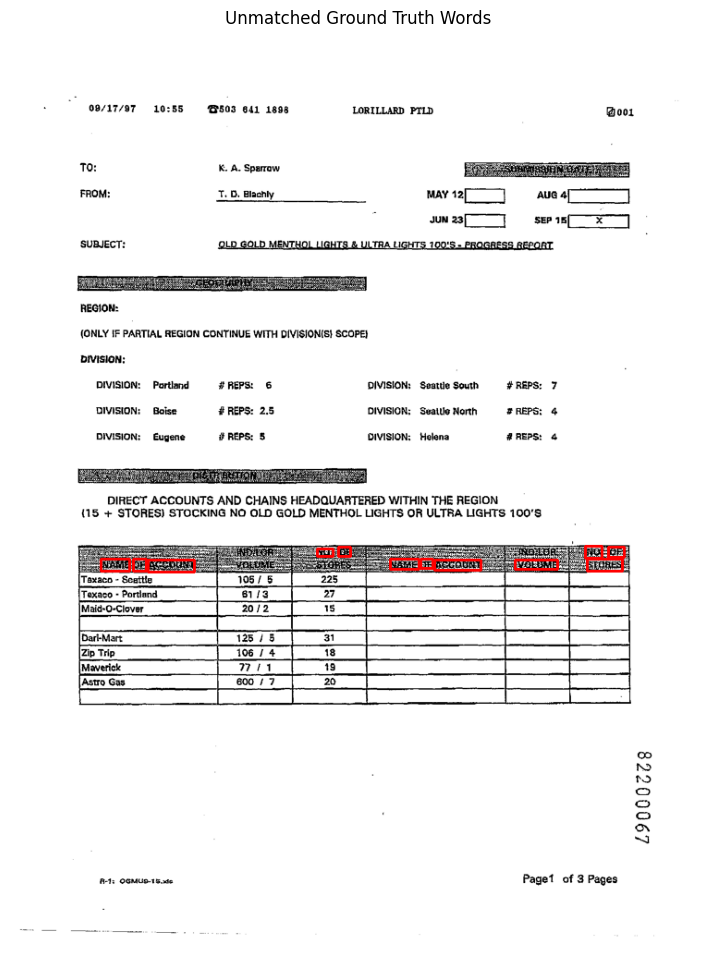

Total Unmatched Words: 12


In [117]:
plt.figure(figsize=(12, 12))

plt.imshow(
    cv2.cvtColor(unmatched_vis, cv2.COLOR_BGR2RGB)
)

plt.title("Unmatched Ground Truth Words")
plt.axis("off")
plt.show()

print("Total Unmatched Words:", len(unmatched_words))



## Improving Table Header OCR Using Image Upscaling



Extract the table header region, upscale it using bicubic interpolation, and compare PaddleOCR text detection before and after resizing.


In [ ]:
# Extract the table header region
h, w = image_vis.shape[:2]

# Approximate table header region
x1 = int(w * 0.10)
x2 = int(w * 0.95)
y1 = int(h * 0.55)
y2 = int(h * 0.63)

table_roi = image_vis[y1:y2, x1:x2]

if table_roi.size == 0:
    raise ValueError("Empty ROI. Check crop coordinates.")

# Upscale the cropped region
table_upscaled = cv2.resize(table_roi,None,fx=3,fy=3,interpolation=cv2.INTER_CUBIC)

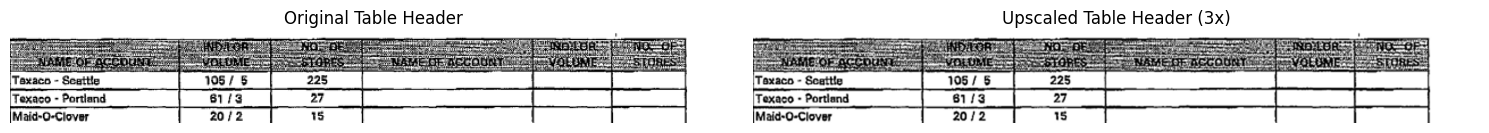

In [120]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].imshow(cv2.cvtColor(table_roi, cv2.COLOR_BGR2RGB))
axes[0].set_title("Original Table Header")

axes[1].imshow(cv2.cvtColor(table_upscaled, cv2.COLOR_BGR2RGB))
axes[1].set_title("Upscaled Table Header (3x)")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


## OCR Comparison Before and After Upscaling





Compare PaddleOCR text recognition on the original and 3x upscaled table header regions to determine whether image upscaling improves the recognition of small text.


In [121]:
# Run OCR on both versions
roi_results = {
    "Original ROI": ocr.predict(table_roi)[0],
    "Upscaled ROI (3x)": ocr.predict(table_upscaled)[0]
}

In [122]:
# Compare extracted texts
roi_comparison = []

for name, result in roi_results.items():

    texts = result["rec_texts"]
    scores = np.asarray(result["rec_scores"])

    print(f"\n{'=' * 50}")
    print(name)
    print(f"{'=' * 50}")

    for text in texts:
        print(text)

    roi_comparison.append({
        "Method": name,
        "Detected Texts": len(texts),
        "Average Confidence": (
            float(scores.mean()) if len(scores) else 0.0
        )
    })


Original ROI
Taxaco - Scattle
105 / 5
225
Texaco - Portland
61/3
27 15
Maid-O-Clover
20/2

Upscaled ROI (3x)
INDEOR
NO DF
INDLOR
UENOOF
NAME OF ACCOUNT
VOLUME
STORES
NAMEOF ACCOUNT
VOLUME
STORES
Texaco -Seattle
105/ 5
225
Texaco • Portland
61/3
27
Maid-O-Clover
20/2
15


In [123]:
roi_comparison_df = pd.DataFrame(roi_comparison)

display(roi_comparison_df)


,Method,Detected Texts,Average Confidence
0,Original ROI,8,0.958241
1,Upscaled ROI (3x),19,0.935945


## Evaluating Multiple Upscaling Factors for Table OCR


# 1x → 2x → 3x → 4x

In [ ]:

# Test different upscaling factors
scales = [1, 2, 3, 4]

scale_results = []
scale_predictions = {}

for scale in scales:

    # Resize image
    if scale == 1:
        resized = table_roi.copy()
    else:
        resized = cv2.resize(table_roi,None,fx=scale,fy=scale,
            interpolation=cv2.INTER_CUBIC
        )

    # Run OCR
    prediction_scale = ocr.predict(resized)[0]

    scale_predictions[scale] = prediction_scale

    texts = prediction_scale["rec_texts"]
    scores = np.asarray(prediction_scale["rec_scores"])

    scale_results.append({
        "Scale": f"{scale}x",
        "Detected Texts": len(texts),
        "Average Confidence": (
            float(scores.mean()) if len(scores) else 0.0
        ),
        "Minimum Confidence": (
            float(scores.min()) if len(scores) else 0.0
        )
    })

    print(f"\n{'=' * 40}")
    print(f"Scale: {scale}x")
    print(f"{'=' * 40}")

    for text in texts:
        print(text)

# Create comparison DataFrame
scale_comparison_df = pd.DataFrame(scale_results)

display(scale_comparison_df)



Scale: 1x
Taxaco - Scattle
105 / 5
225
Texaco - Portland
61/3
27 15
Maid-O-Clover
20/2

Scale: 2x
Texaco - Seattle
105 / 5
225
Texaco - Portland
61/3
27
Maid-O-Clover
20/2
15

Scale: 3x
INDEOR
NO DF
INDLOR
UENOOF
NAME OF ACCOUNT
VOLUME
STORES
NAMEOF ACCOUNT
VOLUME
STORES
Texaco -Seattle
105/ 5
225
Texaco • Portland
61/3
27
Maid-O-Clover
20/2
15

Scale: 4x
INDLOR
AME OF ACCOUNT
VOLUME
ESTORES
NAMEDEACCOUNT
COLUME
Texaco - Seattle
105/5
225
Texaco • Portland
61/3
27
Maid-O-Clover
20/2
15


,Scale,Detected Texts,Average Confidence,Minimum Confidence
0,1x,8,0.958241,0.841708
1,2x,9,0.968096,0.885033
2,3x,19,0.935945,0.663609
3,4x,15,0.952562,0.750813



## Table Header Text Recovery Analysis





Evaluate how different upscaling factors affect the recovery of previously missed table header words.

Use normalized text matching against selected reference header phrases to compare recovery across scales.


In [126]:
# Reference phrases from the table header
header_phrases = [
    "NAME OF ACCOUNT",
    "NUMBER VOLUME",
    "NO OF STORES"
]

def normalize_header(text):
    text = text.upper()
    text = re.sub(r"[^A-Z0-9]+", " ", text)
    return " ".join(text.split())


In [127]:
header_results = []

for scale, result in scale_predictions.items():

    recognized_text = normalize_header(
        " ".join(result["rec_texts"])
    )

    row = {"Scale": f"{scale}x"}

    for phrase in header_phrases:
        normalized_phrase = normalize_header(phrase)

        row[phrase] = normalized_phrase in recognized_text

    row["Recovered Phrases"] = sum(
        row[phrase] for phrase in header_phrases
    )

    header_results.append(row)

header_recovery_df = pd.DataFrame(header_results)

display(header_recovery_df)

,Scale,NAME OF ACCOUNT,NUMBER VOLUME,NO OF STORES,Recovered Phrases
0,1x,False,False,False,0
1,2x,False,False,False,0
2,3x,True,False,False,1
3,4x,False,False,False,0
